In [66]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [67]:
from sklearn.datasets import make_blobs

In [68]:
data = make_blobs(n_samples=400, n_features=2, centers=4, cluster_std=1.7, random_state=42)
type(data)

tuple

In [69]:
data[0].shape

(400, 2)

In [70]:
df = pd.DataFrame(data[0], columns=['feature1', 'feature2'])

<Axes: xlabel='feature1', ylabel='feature2'>

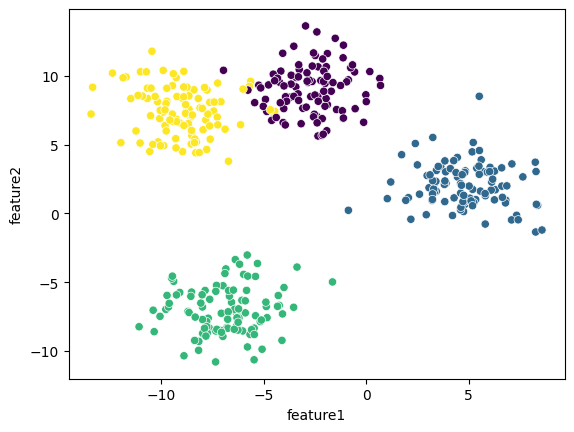

In [71]:
### Visualize
sns.scatterplot(x='feature1',y='feature2',data=df, c=data[1])

In [72]:
# Model Developement
from sklearn.cluster import KMeans

In [73]:
kmeans = KMeans(n_clusters=4,n_init=10)

In [74]:
kmeans.fit(df)

KMeans(n_clusters=4, n_init=10)

In [75]:
kmeans.labels_

array([1, 1, 1, 2, 2, 3, 3, 1, 3, 2, 1, 2, 3, 2, 0, 0, 0, 3, 2, 0, 2, 1,
       3, 2, 3, 1, 0, 3, 0, 1, 1, 2, 1, 1, 3, 0, 2, 2, 3, 0, 3, 1, 1, 0,
       2, 2, 3, 0, 3, 2, 3, 1, 0, 2, 2, 1, 2, 3, 1, 2, 0, 2, 1, 0, 3, 3,
       0, 0, 0, 1, 3, 0, 1, 2, 1, 3, 1, 0, 3, 3, 0, 3, 1, 1, 0, 2, 1, 0,
       3, 0, 2, 3, 1, 0, 2, 1, 3, 0, 0, 3, 0, 2, 3, 0, 0, 0, 2, 0, 2, 3,
       3, 1, 2, 2, 1, 1, 3, 2, 1, 3, 0, 2, 1, 3, 1, 0, 0, 2, 0, 3, 3, 3,
       0, 1, 0, 1, 3, 0, 3, 0, 3, 0, 0, 2, 3, 1, 0, 3, 1, 2, 1, 3, 0, 2,
       0, 3, 2, 3, 2, 3, 2, 3, 2, 1, 2, 1, 0, 1, 1, 1, 1, 3, 0, 0, 0, 2,
       2, 3, 2, 3, 0, 2, 2, 2, 0, 2, 3, 3, 0, 0, 2, 1, 1, 2, 0, 0, 1, 0,
       1, 1, 2, 3, 0, 3, 3, 2, 1, 3, 1, 0, 3, 2, 2, 3, 2, 0, 0, 2, 3, 2,
       0, 3, 3, 2, 0, 3, 0, 3, 0, 3, 0, 3, 2, 1, 1, 0, 3, 1, 2, 0, 3, 3,
       1, 3, 0, 0, 2, 3, 2, 2, 2, 2, 3, 0, 2, 0, 3, 2, 1, 1, 3, 2, 2, 1,
       1, 0, 0, 0, 3, 2, 2, 0, 0, 2, 3, 0, 3, 3, 2, 1, 3, 2, 0, 1, 3, 3,
       1, 1, 1, 2, 2, 1, 2, 2, 0, 1, 3, 3, 2, 1, 1,

In [76]:
kmeans.cluster_centers_

array([[-6.88684301, -7.05669633],
       [-9.21341409,  7.39656047],
       [ 4.82216055,  2.03679148],
       [-2.81918397,  9.00971715]])

<Axes: xlabel='feature1', ylabel='feature2'>

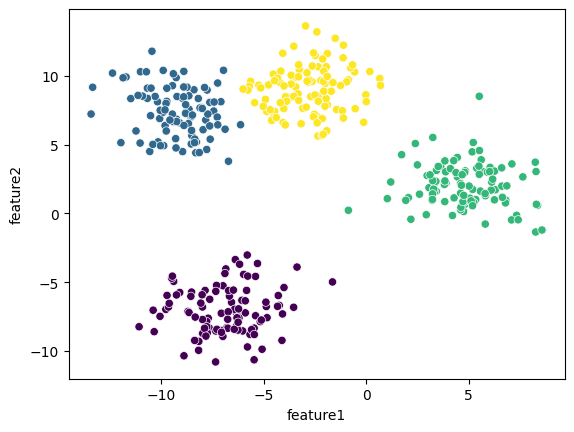

In [77]:
sns.scatterplot(x='feature1',y='feature2',data=df, c=kmeans.labels_)

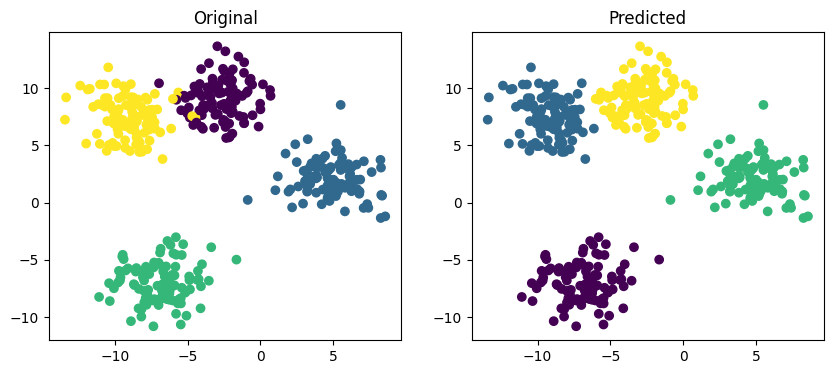

In [85]:
fig, (ax1, ax2) = plt.subplots(1,2,figsize=(10,4))
ax1.set_title('Original')
ax1.scatter(x='feature1',y='feature2',data=df,c=data[1])
ax2.set_title('Predicted')
ax2.scatter(x='feature1',y='feature2',data=df,c=kmeans.labels_)

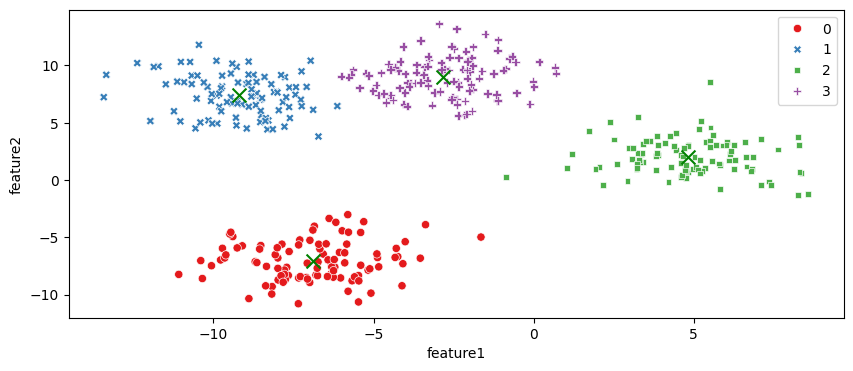

In [99]:
# Centroids
plt.figure(figsize=(10,4))
sns.scatterplot(x='feature1',y='feature2',data=df,hue=kmeans.labels_,style=kmeans.labels_, palette='Set1')
plt.scatter(x=clusters[0,0],y=clusters[0,1],marker='x', c='g',s=100)
plt.scatter(x=clusters[1,0],y=clusters[1,1],marker='x', c='g',s=100)
plt.scatter(x=clusters[2,0],y=clusters[2,1],marker='x', c='g',s=100)
plt.scatter(x=clusters[3,0],y=clusters[3,1],marker='x', c='g',s=100)

In [100]:
kmeans.inertia_

2148.3118662968463

In [102]:
inertia = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k,n_init=10).fit(df)
    inertia.append(kmeans.inertia_)
inertia

[29197.713275837115,
 14487.659121294262,
 4317.298477863249,
 2148.3118662968463,
 1934.5220680510324,
 1724.568119874433,
 1522.9941520867128,
 1318.474734611044,
 1182.1719142403015,
 1053.4220066995408]

Text(0, 0.5, 'WCSS')

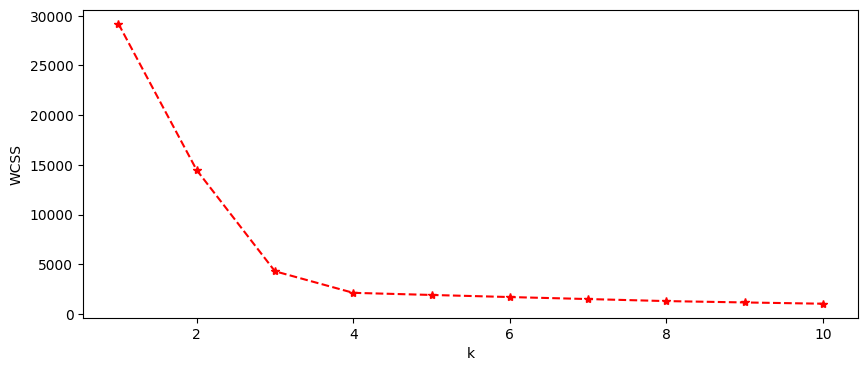

In [106]:
plt.figure(figsize=(10,4))
plt.plot(range(1,11),inertia,'r--*')
plt.xlabel('k')
plt.ylabel('WCSS')